# Week 4 — Logistic Regression and Feature Scaling *(In-depth analysis I)*

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Target:** `target` = 1 if the loan was **charged off**, 0 if **fully paid** (definition and maturity filter in Week 1).
**Prediction point:** loan issuance, so only origination fields are used.

Questions:
1. How well does an interpretable logistic regression separate charged-off from fully paid loans?
2. Does **feature scaling** change the optimization (convergence, iterations, time) and/or predictive performance?
3. Which borrower and loan characteristics have the strongest association with charge-off?

**Protocol (shared with Weeks 5–6):** the same saved train/test split; all preprocessing inside a `Pipeline` so it is fitted on training folds only; hyperparameters tuned by stratified 5-fold CV on training data; the test set is used once for the final comparison. The classification threshold is chosen from **out-of-fold training predictions**, not from the test set.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.exceptions import ConvergenceWarning
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_score,
                             recall_score, f1_score, accuracy_score, confusion_matrix, precision_recall_curve,
                             RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # spurious numpy 2.x + macOS Accelerate warning; results unaffected
import os
os.environ["PYTHONWARNINGS"] = ",".join(f"ignore:{m} encountered in matmul:RuntimeWarning"
                                        for m in ("divide by zero", "overflow", "invalid value"))  # same filter for parallel workers
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
PRIMARY = "roc_auc"   # primary metric; average precision (PR-AUC) reported alongside

scikit-learn 1.6.1


In [2]:
# Classification features: origination fields incl. LendingClub's int_rate and grade.
# Excluded: sub_grade (duplicates grade + rate), installment (function of amount, term, rate).
NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "grade", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]

df = pd.read_parquet(DATA)
df[NUM] = df[NUM].astype(float)
for c in CAT:
    df[c] = df[c].astype("string").fillna("Missing").astype(object)
CAT = [c for c in CAT if df.loc[df.split == "train", c].nunique() > 1]
train, test = df[df.split == "train"], df[df.split == "test"]
X_tr, y_tr = train[NUM + CAT], train["target"].astype(int)
X_te, y_te = test[NUM + CAT], test["target"].astype(int)
print(f"train {X_tr.shape} (charge-off rate {y_tr.mean():.2%}) | test {X_te.shape} (rate {y_te.mean():.2%})")
print(f"A model that predicts 'fully paid' for every loan has accuracy {1 - y_te.mean():.2%}: accuracy alone is not informative.")

train (140000, 24) (charge-off rate 14.87%) | test (60000, 24) (rate 14.87%)
A model that predicts 'fully paid' for every loan has accuracy 85.13%: accuracy alone is not informative.


In [3]:
def make_pre(scale: bool):
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), CAT),
    ])

def metrics(y, score, thr):
    pred = (score >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, score), "PR_AUC(AP)": average_precision_score(y, score),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred), "threshold": thr}

## 1. Feature scaling experiment

The same logistic regression (L2 penalty, C = 1, `lbfgs` solver) is fitted with and without `StandardScaler`, at two iteration limits:

* **default** `max_iter=100`, which shows whether the solver converges at all;
* **generous** `max_iter=2000`, which gives the unscaled model 20× more iterations. If it *still* reports non-convergence, that is itself the finding.

Expectation: unscaled features (loan amount in the tens of thousands next to binary flags) make the loss surface badly conditioned, so lbfgs needs many more iterations or stops early. With an L2 penalty, scaling also changes *which* coefficients are penalized more, so the fitted models can differ slightly.

In [4]:
rows, fitted = [], {}
for scale in [False, True]:
    for max_iter in [100, 2_000]:
        pipe = Pipeline([("pre", make_pre(scale)), ("clf", LogisticRegression(max_iter=max_iter))])
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always", ConvergenceWarning)
            t0 = time.time(); pipe.fit(X_tr, y_tr); secs = time.time() - t0
        converged = not any(issubclass(x.category, ConvergenceWarning) for x in w)
        s = pipe.predict_proba(X_te)[:, 1]
        name = f"{'scaled' if scale else 'unscaled'}, max_iter={max_iter}"
        fitted[name] = pipe
        rows.append({"model": name, "converged": converged, "iterations": int(pipe["clf"].n_iter_[0]),
                     "fit_seconds": secs, "train_ROC_AUC": roc_auc_score(y_tr, pipe.predict_proba(X_tr)[:, 1]),
                     "test_ROC_AUC": roc_auc_score(y_te, s), "test_PR_AUC": average_precision_score(y_te, s)})
scaling_results = pd.DataFrame(rows).set_index("model")
scaling_results

,converged,iterations,fit_seconds,train_ROC_AUC,test_ROC_AUC,test_PR_AUC
model,,,,,,
"unscaled, max_iter=100",False,100,0.8417,0.6724,0.6691,0.2510
"unscaled, max_iter=2000",False,2000,8.8158,0.6809,0.6782,0.2574
"scaled, max_iter=100",True,36,0.7898,0.6848,0.6821,0.2609
"scaled, max_iter=2000",True,36,0.7691,0.6848,0.6821,0.2609


In [5]:
# Do the scaled and unscaled models (max_iter=2000) rank loans the same way?
s_u = fitted["unscaled, max_iter=2000"].predict_proba(X_te)[:, 1]
s_s = fitted["scaled, max_iter=2000"].predict_proba(X_te)[:, 1]
u_conv = bool(scaling_results.loc["unscaled, max_iter=2000", "converged"])
print(f"Correlation of predicted probabilities: {np.corrcoef(s_u, s_s)[0, 1]:.4f}")
print(f"Mean absolute difference in probability: {np.abs(s_u - s_s).mean():.4f}")

Correlation of predicted probabilities: 0.9744
Mean absolute difference in probability: 0.0131


## 2. Hyperparameter tuning (scaled pipeline)

* `C` is the **inverse** regularization strength: a smaller C means a stronger L2 penalty.
* `class_weight='balanced'` reweights charge-offs by roughly 1/prevalence. It usually raises recall at a fixed threshold, but it shifts predicted probabilities upward, so they are no longer calibrated.

Search: 8 values of C × 2 class-weight options × 5 folds, scored on ROC-AUC (refit) and average precision. The test set is not involved.

In [6]:
param_grid = {"clf__C": np.logspace(-5, 2, 8), "clf__class_weight": [None, "balanced"]}
search = GridSearchCV(Pipeline([("pre", make_pre(True)), ("clf", LogisticRegression(max_iter=5000))]),
                      param_grid, scoring={"roc_auc": "roc_auc", "ap": "average_precision"}, refit=PRIMARY,
                      cv=CV, return_train_score=True, n_jobs=-1)
t0 = time.time(); search.fit(X_tr, y_tr); print(f"Grid search: {time.time()-t0:.0f}s")
print("Best params:", search.best_params_, f"| CV ROC-AUC {search.best_score_:.4f}")
if search.best_params_["clf__C"] in (param_grid["clf__C"][0], param_grid["clf__C"][-1]):
    print("NOTE: best C is at the edge of the grid. Extend the grid in that direction and rerun.")

cvres = pd.DataFrame(search.cv_results_)
cvres["class_weight"] = cvres["param_clf__class_weight"].map(str)
cvres["C"] = cvres["param_clf__C"].astype(float)
cvres[["C", "class_weight", "mean_train_roc_auc", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_ap"]].sort_values(["class_weight", "C"])

Grid search: 27s
Best params: {'clf__C': np.float64(0.1), 'clf__class_weight': None} | CV ROC-AUC 0.6839


,C,class_weight,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_ap
0,0.0000,None,0.6769,0.6766,0.0017,0.2541
2,0.0001,None,0.6814,0.6809,0.0014,0.2595
4,0.0010,None,0.6838,0.6830,0.0014,0.2623
6,0.0100,None,0.6848,0.6838,0.0014,0.2633
8,0.1000,None,0.6849,0.6839,0.0014,0.2633
10,1.0000,None,0.6849,0.6839,0.0014,0.2633
12,10.0000,None,0.6849,0.6839,0.0014,0.2633
14,100.0000,None,0.6849,0.6839,0.0014,0.2633
1,0.0000,balanced,0.6778,0.6774,0.0017,0.2551
3,0.0001,balanced,0.6821,0.6816,0.0014,0.2604


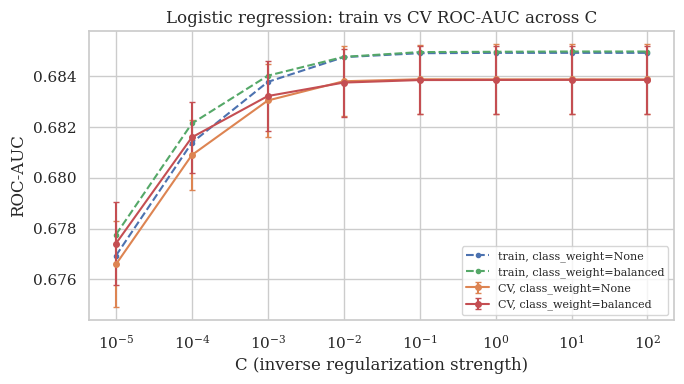

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for cw, g in cvres.groupby("class_weight"):
    ax.plot(g["C"], g["mean_train_roc_auc"], ls="--", marker=".", label=f"train, class_weight={cw}")
    ax.errorbar(g["C"], g["mean_test_roc_auc"], yerr=g["std_test_roc_auc"], marker="o", ms=4, capsize=2, label=f"CV, class_weight={cw}")
ax.set(xscale="log", xlabel="C (inverse regularization strength)", ylabel="ROC-AUC",
       title="Logistic regression: train vs CV ROC-AUC across C")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "week4_C_curve.png", dpi=200); plt.show()

## 3. Choosing a decision threshold (from training data only)

0.50 is a convention, not a business choice. With about one charge-off in every six to eight loans, a 0.50 cut-off flags very few loans. We pick the threshold that maximizes F1 on **out-of-fold** training predictions and then apply it unchanged to the test set. A lender would instead set it from the cost of a missed default versus an unnecessary review.

F1-optimal threshold from out-of-fold predictions: 0.167


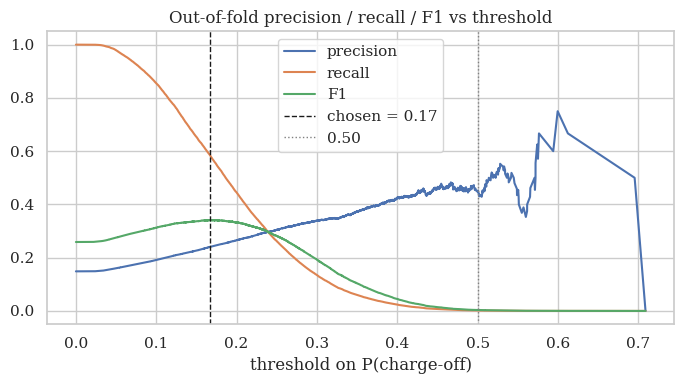

In [8]:
best_lr = search.best_estimator_
oof = cross_val_predict(best_lr, X_tr, y_tr, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, oof)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
THR = float(thr[np.nanargmax(f1[:-1])])
print(f"F1-optimal threshold from out-of-fold predictions: {THR:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, prec[:-1], label="precision"); ax.plot(thr, rec[:-1], label="recall"); ax.plot(thr, f1[:-1], label="F1")
ax.axvline(THR, ls="--", c="k", lw=1, label=f"chosen = {THR:.2f}"); ax.axvline(0.5, ls=":", c="grey", lw=1, label="0.50")
ax.set(xlabel="threshold on P(charge-off)", title="Out-of-fold precision / recall / F1 vs threshold"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Held-out test evaluation

In [9]:
score_te = best_lr.predict_proba(X_te)[:, 1]
score_tr = best_lr.predict_proba(X_tr)[:, 1]
eval_rows = [
    {"model": "unscaled (C=1, " + ("converged" if u_conv else "NOT converged") + ")", **metrics(y_te, s_u, 0.5)},
    {"model": "scaled (C=1)", **metrics(y_te, s_s, 0.5)},
    {"model": "tuned, threshold 0.50", **metrics(y_te, score_te, 0.5)},
    {"model": f"tuned, threshold {THR:.2f}", **metrics(y_te, score_te, THR)},
]
lr_test = pd.DataFrame(eval_rows).set_index("model")
lr_test["Brier"] = [brier_score_loss(y_te, s) for s in [s_u, s_s, score_te, score_te]]
print(f"Tuned model — train ROC-AUC {roc_auc_score(y_tr, score_tr):.4f} | CV {search.best_score_:.4f} | test {roc_auc_score(y_te, score_te):.4f}")
lr_test.to_csv(RES_DIR / "week4_logistic_test_metrics.csv")
lr_test

Tuned model — train ROC-AUC 0.6848 | CV 0.6839 | test 0.6821


,ROC_AUC,PR_AUC(AP),accuracy,precision,recall,F1,threshold,Brier
model,,,,,,,,
"unscaled (C=1, NOT converged)",0.6782,0.2574,0.8513,0.4857,0.0019,0.0038,0.5000,0.1201
scaled (C=1),0.6821,0.2609,0.8514,0.5862,0.0019,0.0038,0.5000,0.1198
"tuned, threshold 0.50",0.6821,0.2609,0.8515,0.6207,0.0020,0.0040,0.5000,0.1198
"tuned, threshold 0.17",0.6821,0.2609,0.6639,0.2391,0.5777,0.3382,0.1671,0.1198


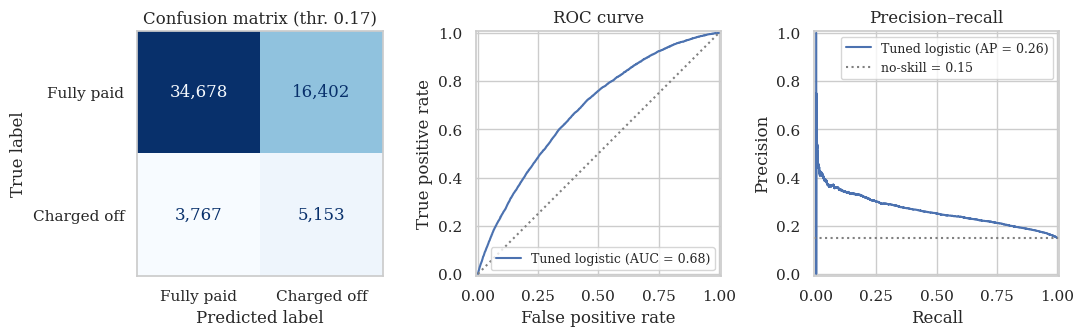

In [10]:
# Figure 3 for the report: confusion matrix + ROC + PR curve (test set)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
ConfusionMatrixDisplay(confusion_matrix(y_te, (score_te >= THR).astype(int)),
                       display_labels=["Fully paid", "Charged off"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title(f"Confusion matrix (thr. {THR:.2f})")
RocCurveDisplay.from_predictions(y_te, score_te, ax=axes[1], name="Tuned logistic")
axes[1].plot([0, 1], [0, 1], ls=":", c="grey"); axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_te, score_te, ax=axes[2], name="Tuned logistic")
axes[2].axhline(y_te.mean(), ls=":", c="grey", label=f"no-skill = {y_te.mean():.2f}"); axes[2].legend(); axes[2].set_title("Precision–recall")
axes[0].grid(False)
axes[1].set(xlabel="False positive rate", ylabel="True positive rate")
axes[2].set(xlabel="Recall", ylabel="Precision")
for a in axes[1:]: a.legend(fontsize=9, loc="lower right" if a is axes[1] else "upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_logistic_evaluation.png", dpi=200); plt.show()

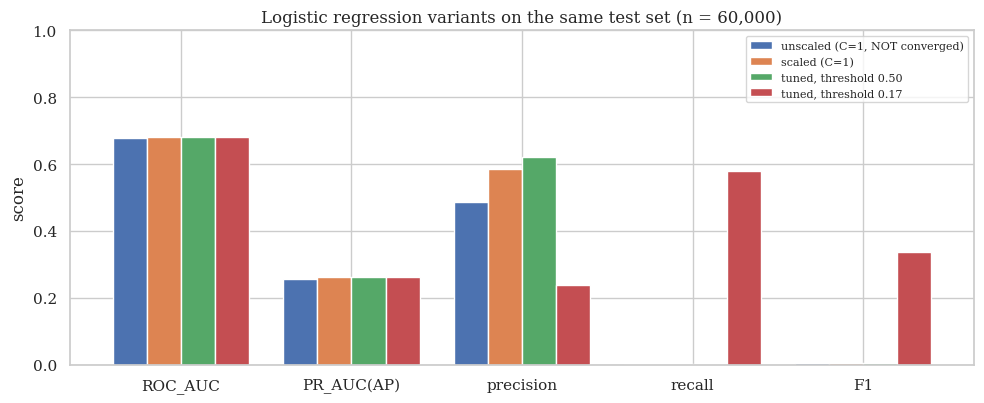

In [11]:
# Figure 4 for the report: unscaled vs scaled vs tuned on identical test rows
plot_cols = ["ROC_AUC", "PR_AUC(AP)", "precision", "recall", "F1"]
ax = lr_test[plot_cols].T.plot.bar(figsize=(10, 4.2), rot=0, width=0.8)
ax.set(title=f"Logistic regression variants on the same test set (n = {len(y_te):,})", ylabel="score", ylim=(0, 1))
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_logistic_comparison.png", dpi=200); plt.show()

## 5. Calibration

A model can rank loans well (high AUC) and still give probabilities that are too high or too low. If the probabilities are to be read as risk estimates, they should lie near the diagonal.

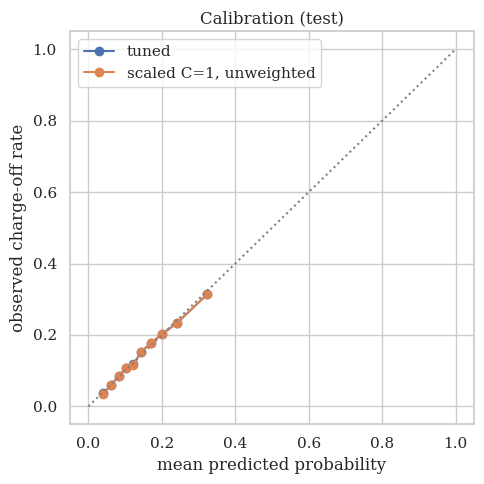

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
for name, s in [("tuned", score_te), ("scaled C=1, unweighted", s_s)]:
    frac, mean_pred = calibration_curve(y_te, s, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=name)
ax.plot([0, 1], [0, 1], ls=":", c="grey"); ax.set(xlabel="mean predicted probability", ylabel="observed charge-off rate", title="Calibration (test)")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Interpreting coefficients as odds ratios

Numeric predictors are standardized, so exp(β) is the multiplicative change in the **odds** of charge-off for a one-standard-deviation increase, holding the other predictors fixed. For a dummy variable, it compares that level to the reference levels. These are associations, not causal effects. Correlated predictors (e.g., `int_rate` and `grade`, `open_acc` and `total_acc`) split their shared effect, so treat individual coefficients in such groups with caution.

,coef,odds_ratio
grade_A,-0.5931,0.5526
term_36,-0.3751,0.6872
application_type_Individual,-0.3714,0.6898
purpose_small_business,0.3086,1.3615
grade_B,-0.2381,0.7881
initial_list_status_f,-0.2107,0.8100
verification_status_Not Verified,-0.2066,0.8133
home_ownership_MORTGAGE,-0.2009,0.8180
initial_list_status_w,-0.1975,0.8208
purpose_credit_card,-0.1888,0.8279


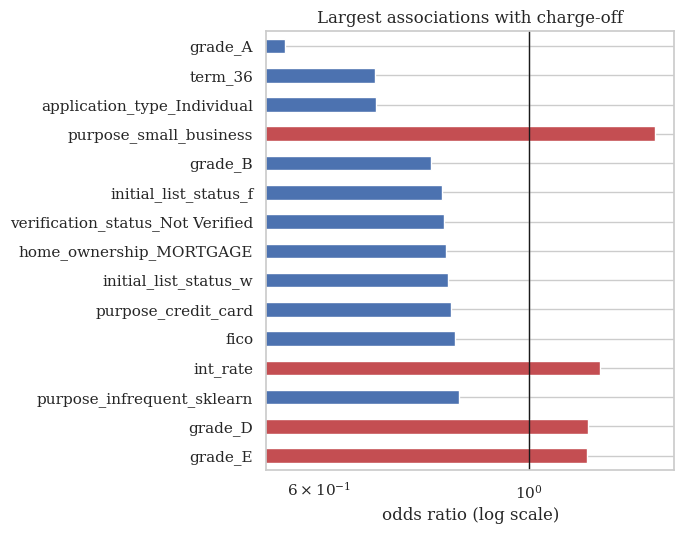

In [13]:
feat = [n.split("__", 1)[-1] for n in best_lr["pre"].get_feature_names_out()]
coef = pd.DataFrame({"coef": best_lr["clf"].coef_[0]}, index=feat)
coef["odds_ratio"] = np.exp(coef["coef"])
top = coef.reindex(coef["coef"].abs().sort_values(ascending=False).index).head(15)
display(top)
ax = top["odds_ratio"].iloc[::-1].plot.barh(figsize=(7, 5.5), color=np.where(top["coef"].iloc[::-1] > 0, "#C44E52", "#4C72B0"))
ax.axvline(1, c="k", lw=1); ax.set(xscale="log", xlabel="odds ratio (log scale)", title="Largest associations with charge-off")
plt.tight_layout(); plt.show()

## 7. Save test-set scores for Weeks 5–6 (same rows, same ids)

In [14]:
pd.DataFrame({"id": test["id"].values, "y": y_te.values, "score": score_te, "threshold": THR}).to_parquet(RES_DIR / "week4_logistic_test_scores.parquet", index=False)
pd.DataFrame({"id": train["id"].values, "y": y_tr.values, "score": score_tr}).to_parquet(RES_DIR / "week4_logistic_train_scores.parquet", index=False)
print("Saved scores for", len(test), "test loans")

Saved scores for 60000 test loans


## 8. Conclusions — *write after running*

* **Scaling:** did the unscaled model converge at `max_iter=100`? Compare iterations and fit time. Once both converged, did test ROC-AUC/PR-AUC differ materially? A likely finding is that scaling mostly improved optimization and changed predictions only slightly. That is a meaningful result, not a failed experiment.
* **Tuning:** which C and class_weight won? Is the CV curve flat (regularization barely matters with this many rows) or peaked?
* **Overfitting:** compare train, CV, and test ROC-AUC for the tuned model. A small gap indicates the model is not overfitting. If all three are only moderate, the limit is the information in the features, not variance.
* **Threshold:** at 0.50 versus the F1-optimal threshold, how do precision and recall change, and what does that mean for a lender (missed defaults vs unnecessary reviews)?
* **Expected vs unexpected:** e.g., expected that `int_rate`/`grade` and 60-month term dominate. Was anything surprising, such as the sign of a coefficient that contradicts EDA, given correlated predictors?
* **Calibration:** are probabilities usable as risk estimates, and did `class_weight='balanced'` distort them?